In [ ]:

from google.colab import files
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Upload the downloaded CSV file
uploaded = files.upload()

# Read the dataset
filename = next(iter(uploaded))
df_raw = pd.read_csv(filename)

# Display dataset information
print("Dataset uploaded successfully!")
print("Dataset shape:", df_raw.shape)

display(df_raw.head())


Saving superstore_sales.csv to superstore_sales.csv
Dataset uploaded successfully!
Dataset shape: (10800, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136
1,2,CA-2017-152156,11/8/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820
2,3,CA-2017-138688,6/12/2017,6/16/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714
3,4,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310
4,5,US-2016-108966,10/11/2016,10/18/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164


In [ ]:

# Create a separate working copy
df = df_raw.copy()

# Remove appended non-transaction records
df = df.dropna(
    subset=["Order Date", "Sales", "Profit", "Category"]
).copy()

# Convert date columns
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce"
)

# Extract Year and Month
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Year-Month"] = df["Order Date"].dt.to_period("M")

# Check cleaned dataset
print("Original rows:", len(df_raw))
print("Cleaned rows:", len(df))
print("Missing values:")
print(df.isnull().sum())

print("\nCleaned dataset:")
display(df.head())


Original rows: 10800
Cleaned rows: 9994
Missing values:
Row ID            0
Order ID          0
Order Date        0
Ship Date         0
Ship Mode         0
Customer ID       0
Customer Name     0
Segment           0
Country           0
City              0
State             0
Postal Code      11
Region            0
Product ID        0
Category          0
Sub-Category      0
Product Name      0
Sales             0
Quantity          0
Discount          0
Profit            0
Year              0
Month             0
Year-Month        0
dtype: int64

Cleaned dataset:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Year,Month,Year-Month
0,1,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.00,41.9136,2017,11,2017-11
1,2,CA-2017-152156,2017-11-08,2017-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.00,219.5820,2017,11,2017-11
2,3,CA-2017-138688,2017-06-12,2017-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.00,6.8714,2017,6,2017-06
3,4,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.45,-383.0310,2016,10,2016-10
4,5,US-2016-108966,2016-10-11,2016-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.20,2.5164,2016,10,2016-10


In [ ]:

# STEP 5: Overall Business Performance

print("========== OVERALL SALES PERFORMANCE ==========")

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_customers = df["Customer ID"].nunique()
total_quantity = df["Quantity"].sum()
average_discount = df["Discount"].mean()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Total Quantity Sold: {total_quantity:,}")
print(f"Average Discount: {average_discount:.2%}")

profit_margin = (total_profit / total_sales) * 100
print(f"Overall Profit Margin: {profit_margin:.2f}%")


========== OVERALL SALES PERFORMANCE ==========
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Total Quantity Sold: 37,873.0
Average Discount: 15.62%
Overall Profit Margin: 12.47%


In [ ]:

# STEP 6: Category-wise Analysis

category_analysis = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Average_Discount=("Discount", "mean")
).round(2)

category_analysis["Profit_Margin_%"] = (
    category_analysis["Total_Profit"] /
    category_analysis["Total_Sales"] * 100
).round(2)

display(category_analysis.sort_values(
    by="Total_Sales", ascending=False
))


,Total_Sales,Total_Profit,Total_Quantity,Average_Discount,Profit_Margin_%
Category,,,,,
Technology,836154.03,145454.95,6939.0,0.13,17.40
Furniture,741999.80,18451.27,8028.0,0.17,2.49
Office Supplies,719047.03,122490.80,22906.0,0.16,17.04


In [ ]:

# Customer Segment Analysis

segment_analysis = df.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Customers=("Customer ID", "nunique")
).round(2)

print("CUSTOMER SEGMENT ANALYSIS")
display(segment_analysis)

# Regional Analysis

region_analysis = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum"),
    Orders=("Order ID", "nunique")
).round(2)

print("REGIONAL ANALYSIS")
display(region_analysis.sort_values(
    by="Sales", ascending=False
))


CUSTOMER SEGMENT ANALYSIS


,Sales,Profit,Customers
Segment,,,
Consumer,1161401.34,134119.21,409
Corporate,706146.37,91979.13,236
Home Office,429653.15,60298.68,148


REGIONAL ANALYSIS


,Sales,Profit,Orders
Region,,,
West,725457.82,108418.45,1611
East,678781.24,91522.78,1401
Central,501239.89,39706.36,1175
South,391721.90,46749.43,822


,Year-Month,Total_Sales,Total_Profit
0,2015-01,14236.8950,2450.1907
1,2015-02,4519.8920,862.3084
2,2015-03,55691.0090,498.7299
3,2015-04,28295.3450,3488.8352
4,2015-05,23648.2870,2738.7096
5,2015-06,34595.1276,4976.5244
6,2015-07,33946.3930,-841.4826
7,2015-08,27909.4685,5318.1050
8,2015-09,81777.3508,8328.0994
9,2015-10,31453.3930,3448.2573


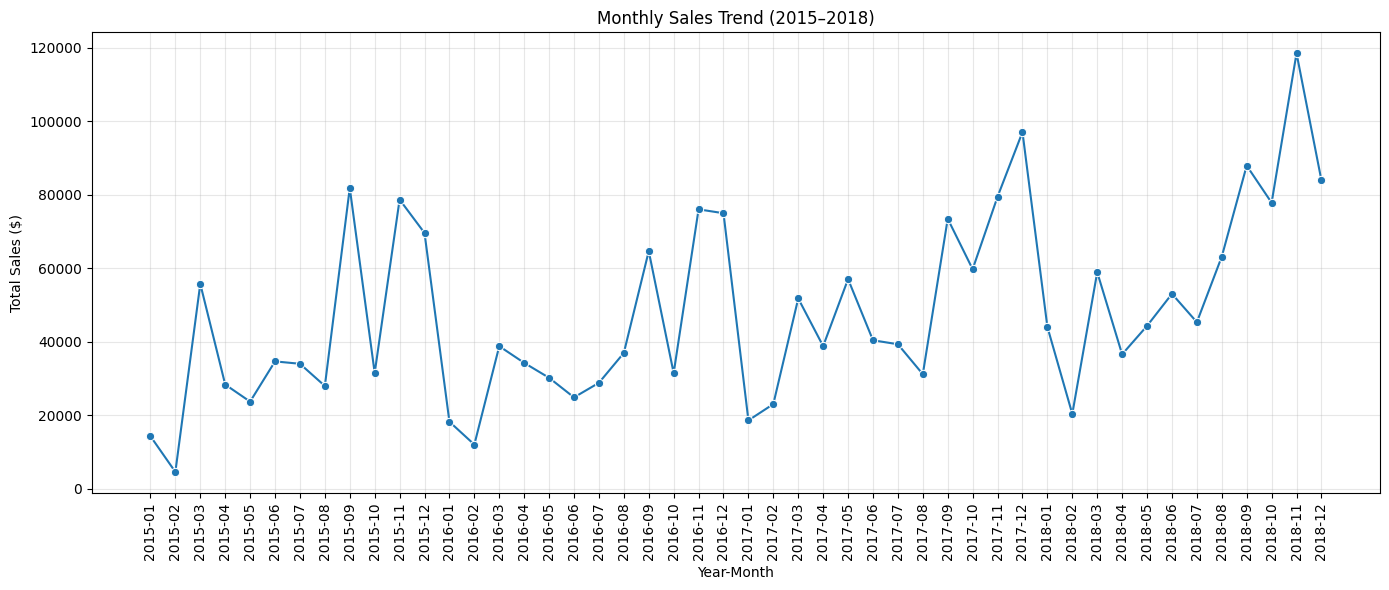

In [ ]:

# STEP 8: Monthly Sales Analysis

monthly_sales = df.groupby("Year-Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
).reset_index()

monthly_sales["Year-Month"] = (
    monthly_sales["Year-Month"].astype(str)
)

display(monthly_sales.head(12))

# Monthly sales trend
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="Year-Month",
    y="Total_Sales",
    marker="o"
)

plt.title("Monthly Sales Trend (2015–2018)")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=90)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


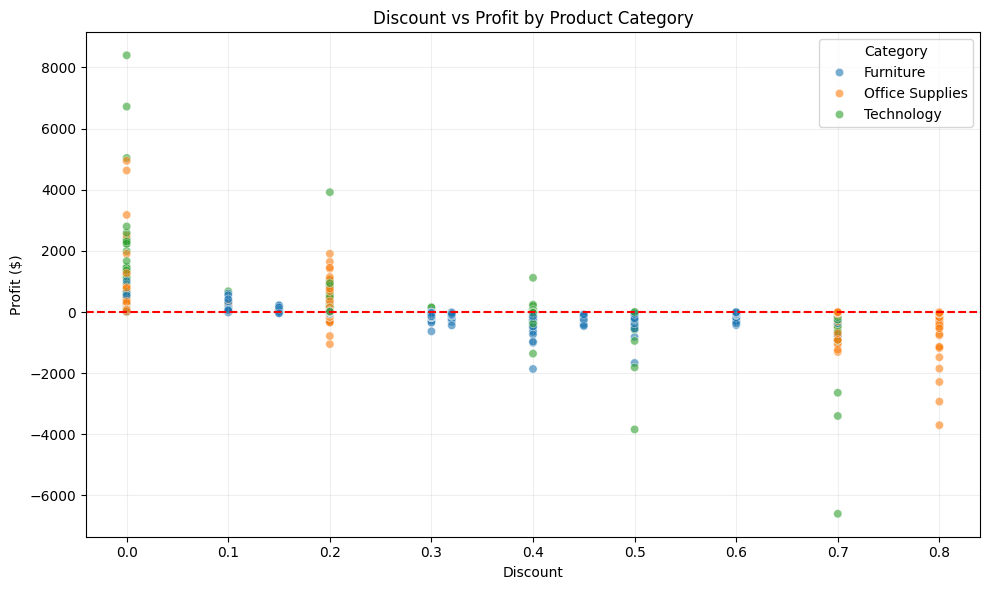

,Average_Profit,Total_Sales,Transactions
Discount,,,
0.00,66.90,1087908.47,4798
0.10,96.06,54369.35,94
0.15,27.29,27558.52,52
0.20,24.70,764594.37,3657
0.30,-45.68,103226.66,227
0.32,-88.56,14493.46,27
0.40,-111.93,116417.78,206
0.45,-226.65,5484.97,11
0.50,-310.70,58918.54,66


In [ ]:

# STEP 9: Discount vs Profit Analysis

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.6
)

plt.title("Discount vs Profit by Product Category")
plt.xlabel("Discount")
plt.ylabel("Profit ($)")
plt.axhline(0, linestyle="--", color="red")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Average profit at each discount level
discount_analysis = df.groupby("Discount").agg(
    Average_Profit=("Profit", "mean"),
    Total_Sales=("Sales", "sum"),
    Transactions=("Profit", "count")
).round(2)

display(discount_analysis)


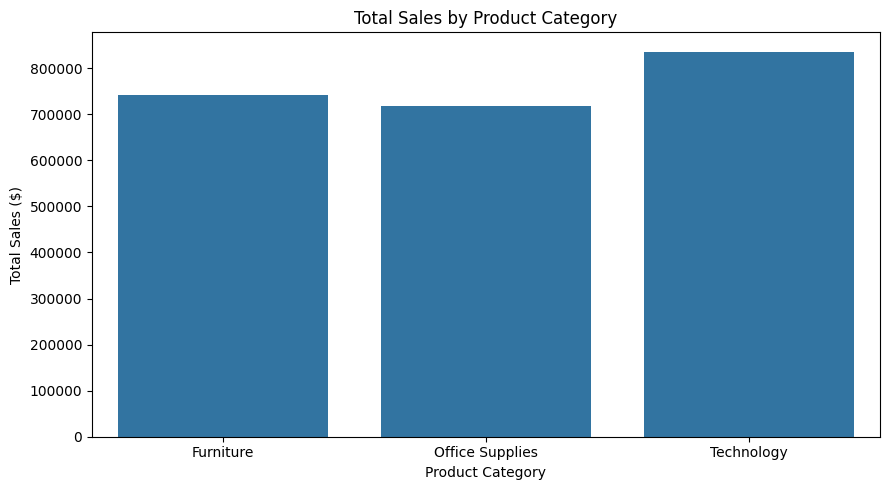

In [ ]:

# STEP 10: Category-wise Sales Chart

plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Category",
    y="Sales",
    estimator=sum,
    errorbar=None
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales ($)")
plt.tight_layout()
plt.show()


In [ ]:

# STEP 11: Executive Business Insights

# 1. Category performance
cat = df.groupby("Category").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

# 2. Customer segment performance
seg = df.groupby("Segment").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

# 3. Regional performance
reg = df.groupby("Region").agg(
    Sales=("Sales", "sum"),
    Profit=("Profit", "sum")
)

# 4. Monthly seasonality
df["Calendar_Month"] = df["Order Date"].dt.month

seasonality = df.groupby("Calendar_Month")["Sales"].sum()
best_month = seasonality.idxmax()

# 5. Discount sensitivity
df["Discount_Band"] = pd.cut(
    df["Discount"],
    bins=[-0.001, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0],
    labels=["0-10%", "10-20%", "20-30%",
            "30-40%", "40-50%", "50-100%"]
)

discount_insights = df.groupby(
    "Discount_Band", observed=True
)["Profit"].mean()

# Print findings
print("========== FIVE EXECUTIVE BUSINESS FINDINGS ==========")

print("\n1. TOP SALES CATEGORY")
print(cat["Sales"].idxmax(),
      "- Sales: $", round(cat["Sales"].max(), 2))

print("\n2. MOST PROFITABLE CATEGORY")
print(cat["Profit"].idxmax(),
      "- Profit: $", round(cat["Profit"].max(), 2))

print("\n3. BEST CUSTOMER SEGMENT BY SALES")
print(seg["Sales"].idxmax(),
      "- Sales: $", round(seg["Sales"].max(), 2))

print("\n4. BEST SALES MONTH ACROSS FOUR YEARS")
print("Month:", best_month,
      "- Total sales: $", round(seasonality.max(), 2))

print("\n5. DISCOUNT SENSITIVITY")
display(discount_insights.round(2))

print("\nTOP SALES REGION")
print(reg["Sales"].idxmax(),
      "- Sales: $", round(reg["Sales"].max(), 2))


========== FIVE EXECUTIVE BUSINESS FINDINGS ==========

1. TOP SALES CATEGORY
Technology - Sales: $ 836154.03

2. MOST PROFITABLE CATEGORY
Technology - Profit: $ 145454.95

3. BEST CUSTOMER SEGMENT BY SALES
Consumer - Sales: $ 1161401.34

4. BEST SALES MONTH ACROSS FOUR YEARS
Month: 11 - Total sales: $ 352461.07

5. DISCOUNT SENSITIVITY


,Profit
Discount_Band,
0-10%,67.46
10-20%,24.74
20-30%,-45.68
30-40%,-109.22
40-50%,-298.70
50-100%,-89.44



TOP SALES REGION
West - Sales: $ 725457.82



# Task 1: Exploratory Data Analysis (EDA) on Superstore Retail Sales

## 1. Project Objective
Analyze Superstore retail sales data to identify revenue trends,
customer behavior, product performance, and discount sensitivity.

## 2. Tools and Technologies
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Google Colab

## 3. Dataset Cleaning
- Original records: 10,800
- Valid sales records: 9,994
- Removed appended non-transaction records: 806
- Missing postal codes: 11
- Converted order and shipping dates into datetime format.
- Extracted year, month and year-month features.

## 4. Exploratory Data Analysis
- Overall sales and profit analysis
- Category-wise revenue analysis
- Customer segment analysis
- Regional performance analysis
- Monthly sales seasonality
- Discount versus profit analysis

## 5. Executive Business Findings


## 6. Conclusion
The analysis identifies differences in product-category
performance, customer segments, regional sales, monthly
sales patterns and discount-related profitability.

These insights can help management improve pricing,
sales planning and business profitability.
